# 02: Exploratory analysis

What do 9+ seasons of Premier League results look like? This notebook sets
the baseline that every model must beat: always predicting a home win.

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

matches = pd.read_csv(
    "../data/processed/matches.csv",
    parse_dates=["Date"],
    dtype={"Season": str},
)
sns.set_theme()
matches.shape, matches["Date"].dtype

((3520, 22), dtype('<M8[ns]'))

1. How often does each result happen? (bar chart)

In [ ]:
matches['FTR'].value_counts(normalize=True)

FTR
H    1551
A    1143
D     826
Name: count, dtype: int64

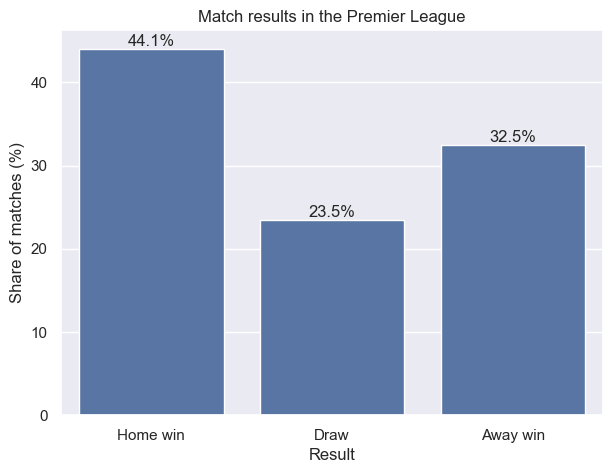

In [8]:
# Share of each result (H, D, A), in a fixed order
result_share = matches["FTR"].value_counts(normalize=True).reindex(["H", "D", "A"])

# Friendlier labels
result_share.index = ["Home win", "Draw", "Away win"]

# Plot
plt.figure(figsize=(7, 5))
ax = sns.barplot(x=result_share.index, y=result_share.values * 100)
plt.title("Match results in the Premier League")
plt.xlabel("Result")
plt.ylabel("Share of matches (%)")

# Show the percentage on top of each bar
for bar in ax.patches:
    ax.annotate(f"{bar.get_height():.1f}%",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha="center", va="bottom")

from pathlib import Path
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/result_shares.png", dpi=150, bbox_inches="tight")

plt.show()

In [7]:
baseline = result_share["Home win"]
print(f"Baseline accuracy (always predict home win): {baseline:.1%}")

Baseline accuracy (always predict home win): 44.1%


2. has home advantage changed over the seasons?

In [9]:
home_win_rate = (
    (matches["FTR"] == "H")        # True/False for each match
    .groupby(matches["Season"])    # split into seasons
    .mean()                        # share of True = home win rate
)
home_win_rate

Season
1718    0.455263
1819    0.476316
1920    0.452632
2021    0.378947
2122    0.428947
2223    0.484211
2324    0.460526
2425    0.407895
2526    0.426316
2627    0.420000
Name: FTR, dtype: float64

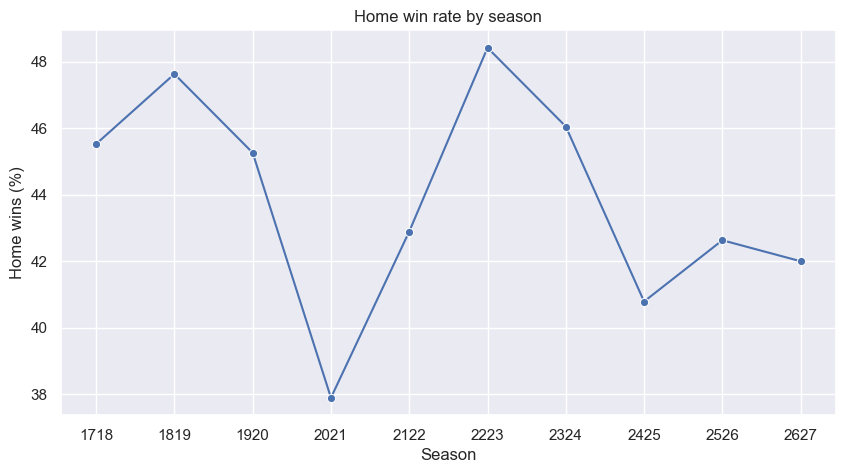

In [10]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=home_win_rate.index, y=home_win_rate.values * 100, marker="o")
plt.title("Home win rate by season")
plt.xlabel("Season")
plt.ylabel("Home wins (%)")
plt.show()

Home win rate was 45% in 2017/18 and 42% in 2025/26, with a noticeable dip in 2020/21 when stadiums were empty.

3. how many goals per game each season?

In [11]:
matches["TotalGoals"] = matches["FTHG"] + matches["FTAG"]

goals_per_game = matches.groupby("Season")["TotalGoals"].mean()
goals_per_game

Season
1718    2.678947
1819    2.821053
1920    2.721053
2021    2.694737
2122    2.818421
2223    2.852632
2324    3.278947
2425    2.934211
2526    2.750000
2627    2.730000
Name: TotalGoals, dtype: float64

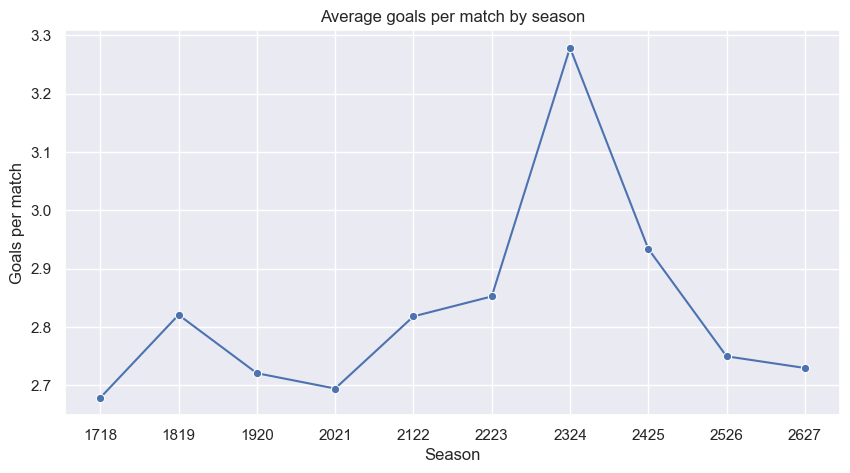

In [12]:
plt.figure(figsize=(10, 5))
sns.lineplot(x=goals_per_game.index, y=goals_per_game.values, marker="o")
plt.title("Average goals per match by season")
plt.xlabel("Season")
plt.ylabel("Goals per match")
plt.show()

4. which teams have the best home record?

In [13]:
# Points the home team earned in each match: win = 3, draw = 1, loss = 0
matches["HomePoints"] = matches["FTR"].map({"H": 3, "D": 1, "A": 0})

home_record = (
    matches.groupby("HomeTeam")
    .agg(home_matches=("FTR", "count"),
         home_win_rate=("FTR", lambda s: (s == "H").mean()),
         home_ppg=("HomePoints", "mean"))
)

# Keep only teams with enough home matches to be meaningful
home_record = home_record[home_record["home_matches"] >= 40]

top10 = home_record.sort_values("home_ppg", ascending=False).head(10)
top10

,home_matches,home_win_rate,home_ppg
HomeTeam,,,
Man City,176,0.789773,2.482955
Liverpool,176,0.710227,2.340909
Arsenal,176,0.681818,2.215909
Man United,176,0.568182,1.920455
Chelsea,176,0.517045,1.823864
Tottenham,176,0.545455,1.772727
Aston Villa,138,0.492754,1.688406
Newcastle,176,0.465909,1.625000
Brentford,100,0.420000,1.560000


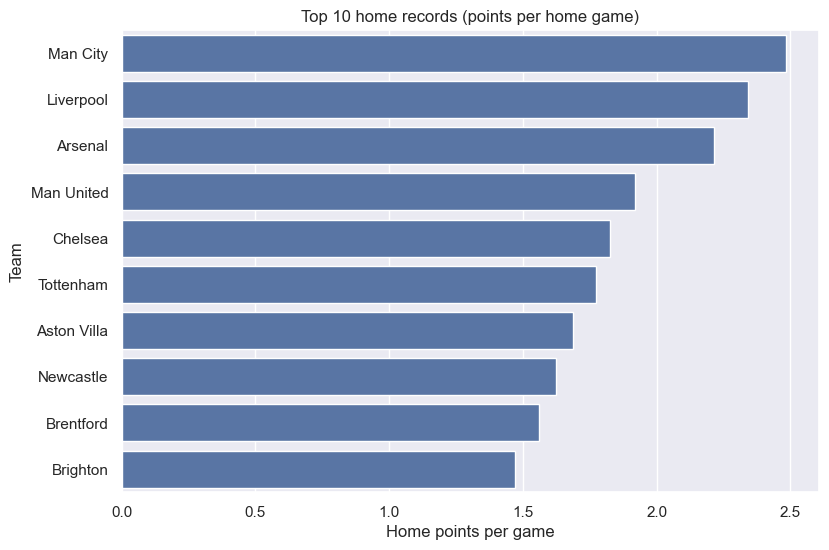

In [14]:
plt.figure(figsize=(9, 6))
sns.barplot(x=top10["home_ppg"], y=top10.index, orient="h")
plt.title("Top 10 home records (points per home game)")
plt.xlabel("Home points per game")
plt.ylabel("Team")
plt.show()

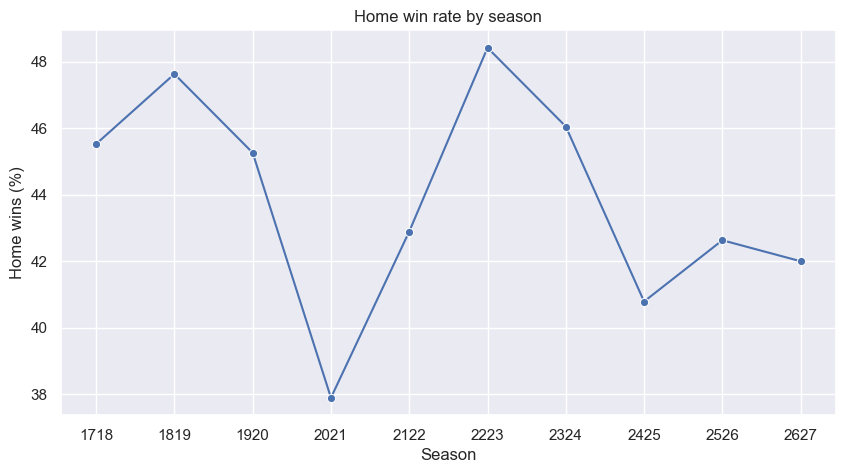

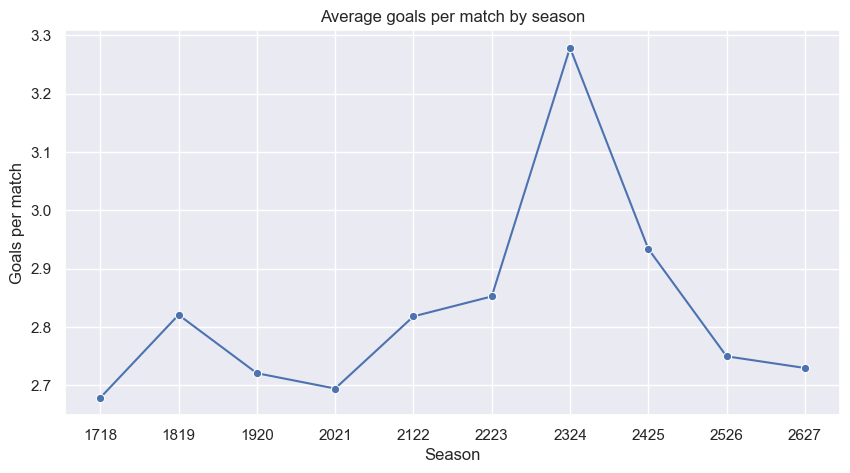

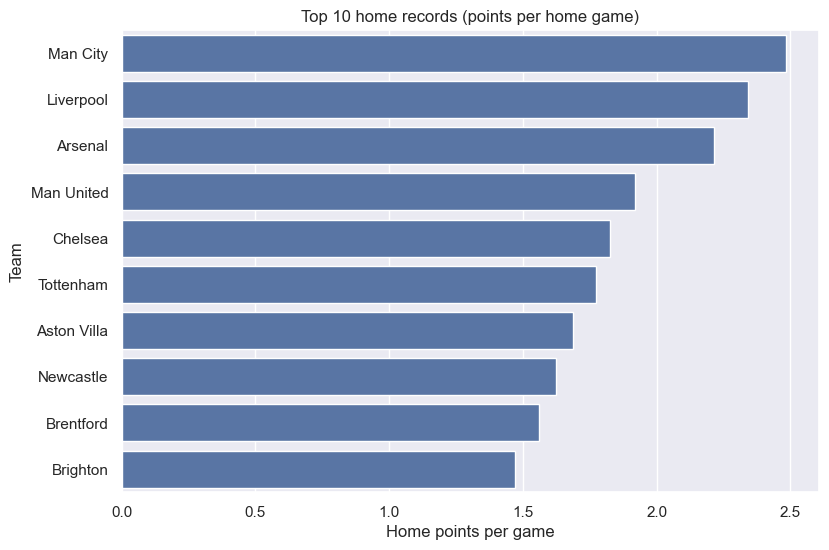

In [15]:
from pathlib import Path
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

# Question 2: home win rate by season
home_win_rate = (matches["FTR"] == "H").groupby(matches["Season"]).mean()
plt.figure(figsize=(10, 5))
sns.lineplot(x=home_win_rate.index, y=home_win_rate.values * 100, marker="o")
plt.title("Home win rate by season")
plt.xlabel("Season")
plt.ylabel("Home wins (%)")
plt.savefig("../reports/figures/home_win_rate_by_season.png", dpi=150, bbox_inches="tight")
plt.show()

# Question 3: goals per match by season
matches["TotalGoals"] = matches["FTHG"] + matches["FTAG"]
goals_per_game = matches.groupby("Season")["TotalGoals"].mean()
plt.figure(figsize=(10, 5))
sns.lineplot(x=goals_per_game.index, y=goals_per_game.values, marker="o")
plt.title("Average goals per match by season")
plt.xlabel("Season")
plt.ylabel("Goals per match")
plt.savefig("../reports/figures/goals_per_game.png", dpi=150, bbox_inches="tight")
plt.show()

# Question 4: top 10 home records
matches["HomePoints"] = matches["FTR"].map({"H": 3, "D": 1, "A": 0})
home_record = matches.groupby("HomeTeam").agg(
    home_matches=("FTR", "count"),
    home_ppg=("HomePoints", "mean"),
)
home_record = home_record[home_record["home_matches"] >= 40]
top10 = home_record.sort_values("home_ppg", ascending=False).head(10)
plt.figure(figsize=(9, 6))
sns.barplot(x=top10["home_ppg"], y=top10.index, orient="h")
plt.title("Top 10 home records (points per home game)")
plt.xlabel("Home points per game")
plt.ylabel("Team")
plt.savefig("../reports/figures/top_home_records.png", dpi=150, bbox_inches="tight")
plt.show()

5. do more shots on target mean more goals?

     avg_goals  n_matches
HST                      
0         0.05         75
1         0.39        208
2         0.64        411
3         1.03        525
4         1.29        547
5         1.62        519
6         2.02        441
7         2.33        304
8         2.50        183
9         2.90        129
10        3.05         83
11        3.20         45
12        3.50         24
13        3.53         15


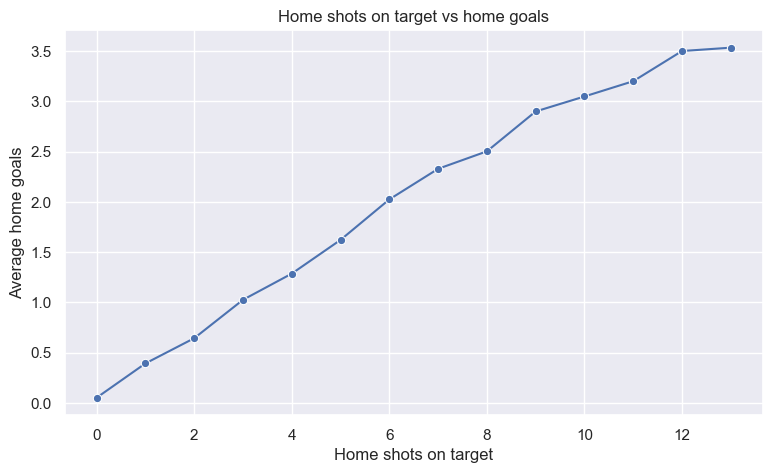

,HST,FTHG
HST,1.000000,0.602041
FTHG,0.602041,1.000000


In [16]:
from pathlib import Path
Path("../reports/figures").mkdir(parents=True, exist_ok=True)

# Average home goals for each number of home shots on target
shots_vs_goals = (
    matches.groupby("HST")["FTHG"]
    .agg(avg_goals="mean", n_matches="count")
)

# Drop rare values (e.g. 18 shots on target) that rest on very few matches
shots_vs_goals = shots_vs_goals[shots_vs_goals["n_matches"] >= 10]
print(shots_vs_goals.round(2))

plt.figure(figsize=(9, 5))
sns.lineplot(x=shots_vs_goals.index, y=shots_vs_goals["avg_goals"], marker="o")
plt.title("Home shots on target vs home goals")
plt.xlabel("Home shots on target")
plt.ylabel("Average home goals")
plt.savefig("../reports/figures/shots_vs_goals.png", dpi=150, bbox_inches="tight")
plt.show()

# How strong is the link?
matches[["HST", "FTHG"]].corr()